<div style="background: linear-gradient(135deg, #003366 0%, #0055a5 100%); border-radius: 12px; padding: 18px 26px; display: flex; align-items: center; gap: 24px; box-shadow: 0 4px 12px rgba(0,0,0,0.2);">
    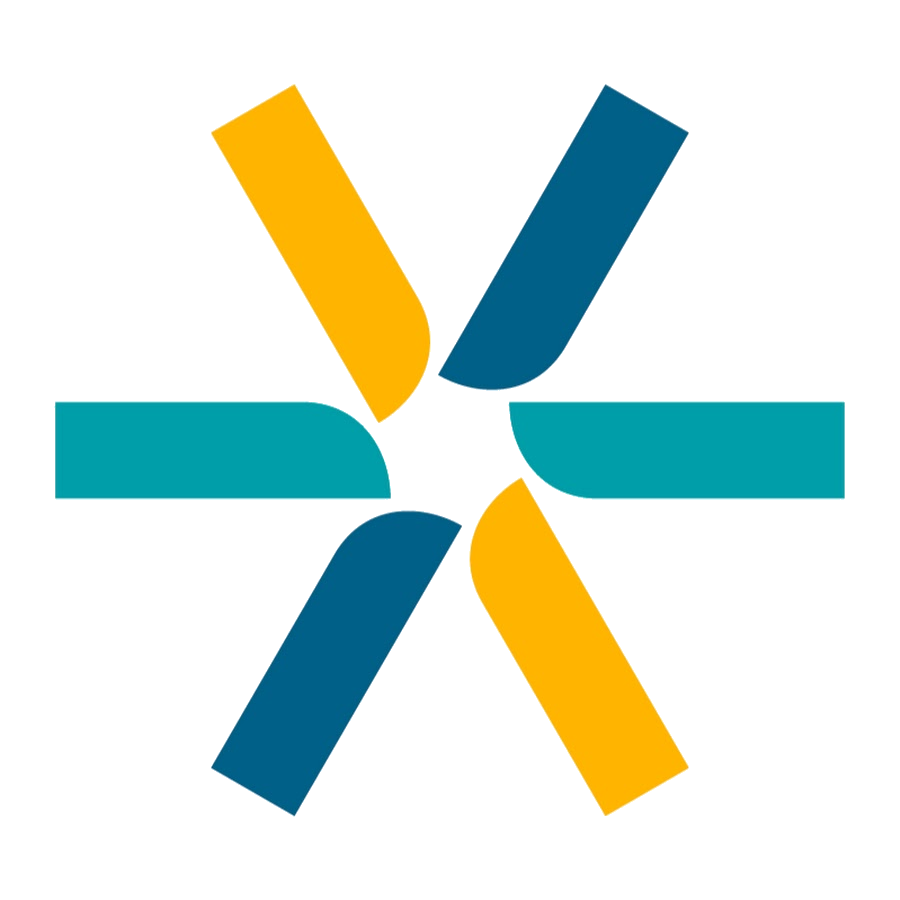
    <div>
        <h1 style="margin: 0; color: #ffffff; font-size: 1.45em; letter-spacing: 0.5px;">Aprendizaje Automático y Grandes Datos</h1>
        <h2 style="margin: 6px 0 2px 0; color: #cce4ff; font-size: 1.15em; font-weight: normal;">Agrupamiento particional y jerárquico · demanda eléctrica (CAMMESA)</h2>
        <h3 style="margin: 0 0 8px 0; color: #a8d0f5; font-size: 1em; font-weight: normal;">Unidad 8 · Aprendizaje no supervisado</h3>
        <span style="background: #ffd700; color: #003366; font-weight: bold; font-size: 0.9em; padding: 3px 12px; border-radius: 20px;">⚡ Grupo 6 · Clase 41 sobre nuestro dataset</span>
    </div>
</div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Antes de empezar</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">La pregunta</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Cambia: ya no hay una columna que predecir. Con los agentes del mercado eléctrico, sin usar el tipo de agente ni la tarifa: ¿hay grupos de agentes que se comportan parecido, cuántos, y cómo son?</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Los datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Cada fila ya no es un mes sino <b>un agente en una tarifa</b> (una serie), con su comportamiento resumido en seis números calculados sobre toda su historia: tamaño, estacionalidad (verano contra invierno), volatilidad, tendencia, frecuencia de caídas fuertes y variabilidad. Son 868 series con al menos 24 meses de datos. La tarifa y el tipo de agente se guardan aparte: no entran, y al final se comparan con los grupos.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se quiere resolver</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">k-medias por adentro (asignar y mover, adónde converge, k-means++), cómo se elige k (codo, silueta y su diagrama) y sus límites; el aglomerativo con sus enlaces y el dendrograma; el bisectivo; y qué algoritmo para qué forma de datos. Iris y las tres geometrías construidas del material aparecen igual que en la cátedra.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo que se muestra</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Las mismas secciones de la clase 41: 1 · los datos → A · centroides → B · cuántos → C · fusionar → D · dividir → E · comparativo → F · usarlo: los grupos de agentes descritos, un agente nuevo, diez agentes.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Cómo se decide</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Sin etiquetas no hay exactitud ni AUC: se mide con la inercia y la silueta, y se mira qué significan los grupos.</td></tr></table></div>

<div style="background: #fdecea; border-left: 5px solid #c0392b; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #c0392b; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">⚠️</span><b style="color: #003366; margin-left: 8px;">Qué hay que saber de estos datos antes de agrupar</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Hubo que construir las filas.</b> El CSV tiene una fila por agente y por mes. Para agrupar agentes hace falta una fila por agente, así que cada serie se resume en seis números. Esa elección define qué significa «parecido»: dos agentes se parecen si tienen tamaño, estacionalidad y volatilidad parecidos, no si sus curvas mes a mes coinciden.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>La estructura es más clara que la de los socios del gimnasio,</b> pero no nítida: la silueta es ~0,38 con dos grupos y ~0,30 con tres. Hay agentes extremos (un consumo que se multiplica por cinco en verano, otro que cae a casi cero) que pueden quedarse con un grupo para ellos solos; se ve en B.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>No hay corte temporal.</b> Agrupar no predice nada, así que se usa toda la historia de cada serie.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">1 · Los datos, sin etiquetas</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Un perfil por serie, escalado; e iris, el ejemplo del material</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Para cada serie (agente + tarifa) con 24 meses o más y casi sin meses en cero: <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">log_tamano</code> (log₁₀ de la demanda media), <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">estacionalidad</code> (log₂ de verano / invierno: +1 es el doble en verano, −1 el doble en invierno), <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">volatilidad</code> (la mediana del cambio mensual absoluto), <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">tendencia_anual</code> (pendiente del log₁₀ de la demanda por año), <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">frac_caidas</code> (qué fracción de los meses cayó más de 15 %: el objetivo de las clases 32 a 40, resumido) y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">cv</code> (desvío / media). Escaladas. La tarifa y el tipo de agente, aparte.</p></div>

In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, BisectingKMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.datasets import load_iris, make_blobs, make_moons

AZUL, AMBAR, GRIS, ROJO, VERDE, VIOLETA = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57", "#7c3aed"
COLORES = [AZUL, ROJO, VERDE, AMBAR, VIOLETA, "#0e7490", "#be185d", "#4d7c0f"]
pd.set_option("display.width", 130)
np.set_printoptions(suppress=True, precision=3)

CANDIDATAS = [Path("datos/demanda-ltimos-aos.csv"), Path("demanda-ltimos-aos.csv"), Path("../datos/demanda-ltimos-aos.csv"), Path("../Regresion/datos/demanda-ltimos-aos.csv")]
RUTA = next((p for p in CANDIDATAS if p.exists()), None)
if RUTA is None:
    raise FileNotFoundError(f"No encontré el CSV. Ponelo en alguna de estas rutas: {[str(p) for p in CANDIDATAS]}")
demanda = pd.read_csv(RUTA, encoding="utf-8-sig", dtype={"indice_tiempo": str})
demanda["periodo"] = pd.PeriodIndex(demanda["indice_tiempo"], freq="M")
demanda["serie"] = demanda["agente_nemo"] + " | " + demanda["tarifa"]
demanda = demanda.sort_values(["serie", "periodo"])

def perfil(g):
    """Seis números que resumen cómo se comporta la demanda de una serie a lo largo de su historia."""
    s = g.set_index("periodo")["demanda_MWh"]
    if len(s) < 24 or (s <= 0).mean() > 0.1:
        return None                                                            # muy corta, o con muchos meses en cero
    pos = s[s > 0]
    cambio = (s / s.shift(1) - 1)[s.shift(1) > 0].clip(-1, 3)                  # variación mensual, recortada como en la clase 32
    mes = pos.index.month
    verano, invierno = pos[np.isin(mes, [12, 1, 2])].mean(), pos[np.isin(mes, [6, 7, 8])].mean()
    anios = np.array([(p - pos.index[0]).n for p in pos.index]) / 12
    return pd.Series({"log_tamano": np.log10(pos.mean()),
                      "estacionalidad": np.log2(verano / invierno),
                      "volatilidad": cambio.abs().median(),
                      "tendencia_anual": np.polyfit(anios, np.log10(pos.to_numpy()), 1)[0],
                      "frac_caidas": (cambio < -0.15).mean(),
                      "cv": pos.std() / pos.mean(),
                      "meses": len(s)})
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    perfiles = demanda.groupby("serie").apply(perfil).dropna()
COLUMNAS = ["log_tamano", "estacionalidad", "volatilidad", "tendencia_anual", "frac_caidas", "cv"]
etiquetas_reales = demanda.groupby("serie")[["categoria_demanda", "categoria_tarifa", "tipo_agente", "region"]].first().loc[perfiles.index]
tarifa = etiquetas_reales["categoria_tarifa"]                                    # se guarda aparte; no entra
escalador = StandardScaler().fit(perfiles[COLUMNAS])
Z = escalador.transform(perfiles[COLUMNAS])                                      # lo que ven los algoritmos: 868 × 6, media 0 y desvío 1 por columna
print(f"{demanda['serie'].nunique()} series en el CSV · {len(perfiles)} con 24 meses o más · {Z.shape[1]} columnas escaladas")
print(f"La tarifa (no se usa): {tarifa.value_counts().to_dict()} · el tipo de agente (tampoco): {etiquetas_reales['categoria_demanda'].value_counts().to_dict()}")
display(perfiles[COLUMNAS].describe().round(3))

iris = load_iris()
km_iris = KMeans(n_clusters=3, n_init=10, random_state=2026).fit(iris.data)
print("Iris sin etiquetas, k-medias con k = 3, contra la especie que el algoritmo nunca vio:")
display(pd.crosstab(pd.Series(km_iris.labels_, name="grupo"), pd.Series(iris.target_names[iris.target], name="especie")))

1768 series en el CSV · 868 con 24 meses o más · 6 columnas escaladas
La tarifa (no se usa): {'Industrial/Comercial Grande': 526, 'Residencial': 267, 'Comercial': 75} · el tipo de agente (tampoco): {'Gran Usuario': 461, 'Distribuidor': 407}


,log_tamano,estacionalidad,volatilidad,tendencia_anual,frac_caidas,cv
count,868.000,868.000,868.000,868.000,868.000,868.000
mean,3.219,0.017,0.107,0.013,0.132,0.261
std,0.921,0.406,0.086,0.157,0.103,0.225
min,-0.740,-2.240,0.000,-1.033,0.000,0.029
25%,2.779,-0.194,0.058,-0.032,0.054,0.125
50%,3.212,-0.005,0.086,-0.002,0.114,0.195
75%,3.732,0.198,0.125,0.047,0.189,0.316
max,5.888,2.577,0.988,1.168,0.533,1.887


Iris sin etiquetas, k-medias con k = 3, contra la especie que el algoritmo nunca vio:


especie,setosa,versicolor,virginica
grupo,,,
0,0,2,36
1,50,0,0
2,0,48,14


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Cómo se ven los perfiles</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cada columna, y la correlación entre ellas. Un agente es un punto en seis dimensiones; acá, de a una y de a pares.</p></div>

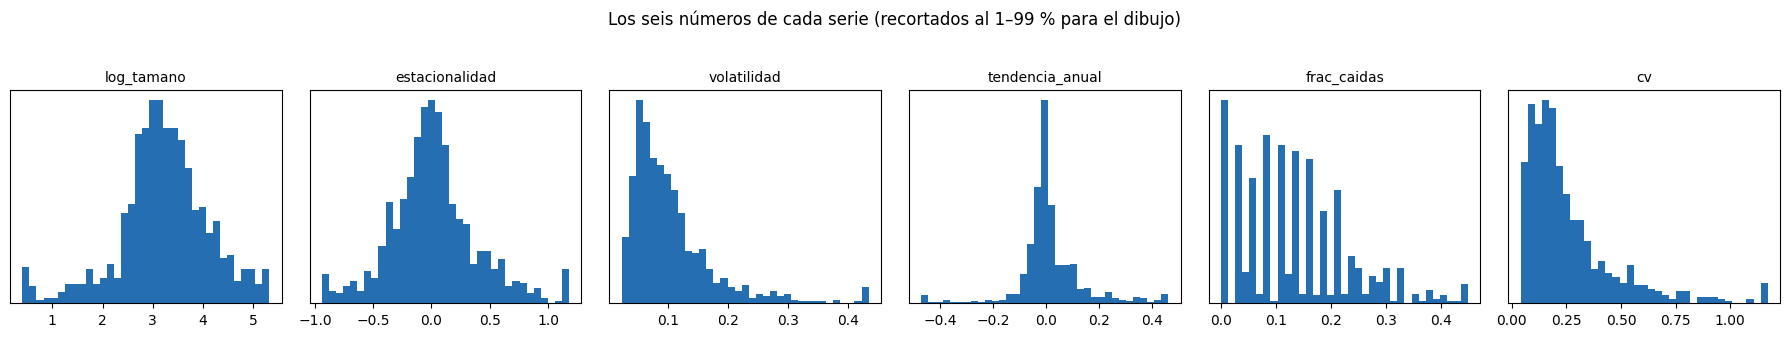

Correlaciones:


,log_tamano,estacionalidad,volatilidad,tendencia_anual,frac_caidas,cv
log_tamano,1.00,0.01,-0.22,-0.15,-0.24,-0.37
estacionalidad,0.01,1.00,0.06,0.07,-0.01,0.09
volatilidad,-0.22,0.06,1.00,0.15,0.77,0.62
tendencia_anual,-0.15,0.07,0.15,1.00,-0.05,0.10
frac_caidas,-0.24,-0.01,0.77,-0.05,1.00,0.58
cv,-0.37,0.09,0.62,0.10,0.58,1.00


In [3]:
fig, ejes = plt.subplots(1, 6, figsize=(18, 3.2))
for ax, col in zip(ejes, COLUMNAS):
    v = perfiles[col]; ax.hist(v.clip(*v.quantile([0.01, 0.99])), bins=35, color=AZUL, alpha=0.85); ax.set_title(col, fontsize=10); ax.set_yticks([])
fig.suptitle("Los seis números de cada serie (recortados al 1–99 % para el dibujo)", y=1.04)
plt.tight_layout(); plt.show()
print("Correlaciones:"); display(perfiles[COLUMNAS].corr().round(2))

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El tamaño es casi una campana (en log). La estacionalidad está centrada en cero: hay agentes que consumen más en verano (aire acondicionado) y otros más en invierno (calefacción eléctrica, o actividades que paran en verano). La volatilidad, la frecuencia de caídas y la variabilidad tienen colas largas y están correlacionadas entre sí (0,6–0,8): tres maneras de medir «qué tan estable es». Eso pesa en la distancia: la estabilidad cuenta casi tres veces.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">A · Centroides: k-medias y k-means++</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.1 · Asignar y mover, a mano</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El algoritmo de la diapositiva sobre las cinco nubes construidas del material, igual que en la cátedra.</p></div>

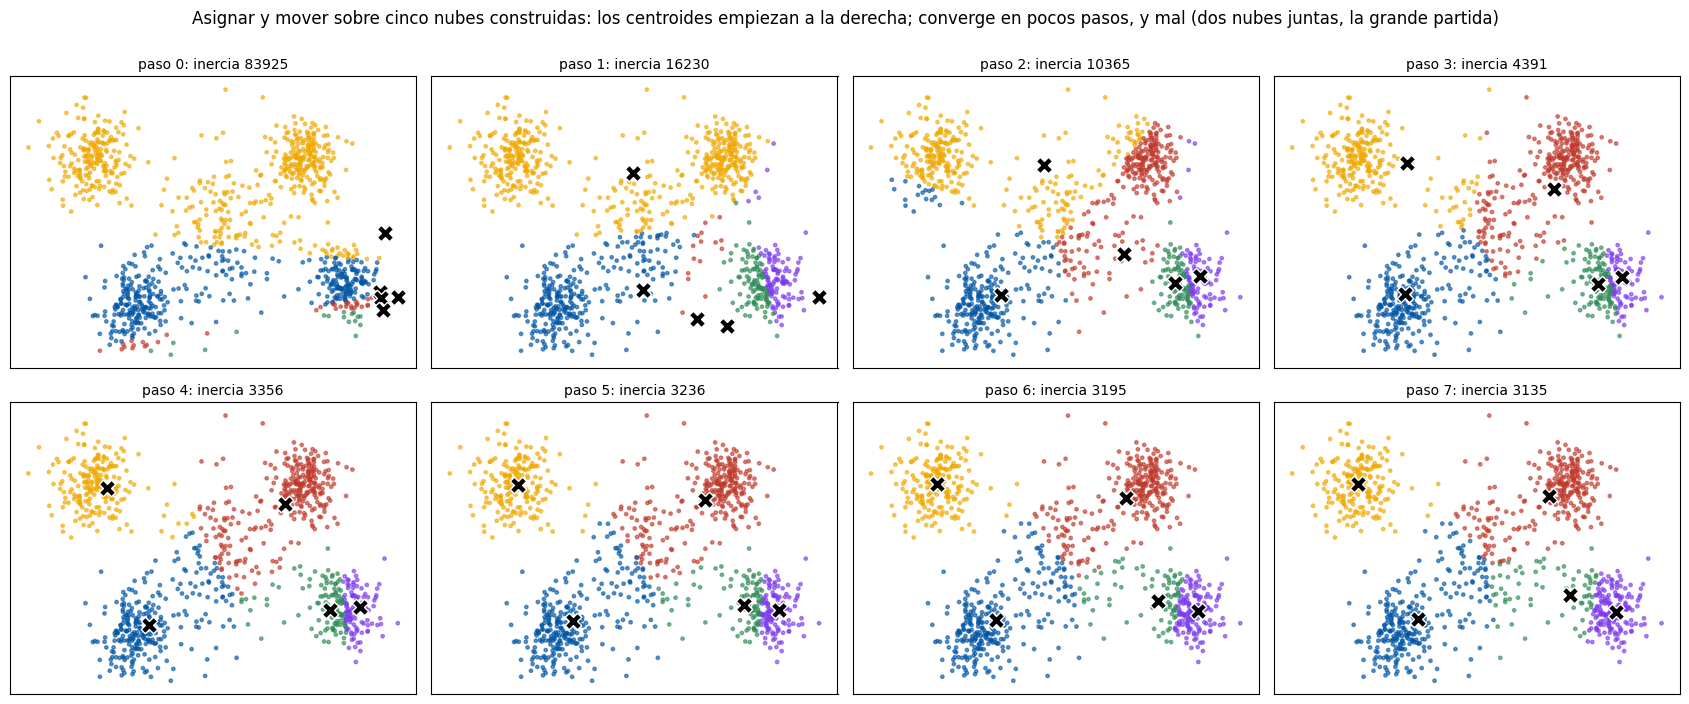

Inercia por paso: [83925, 16230, 10365, 4391, 3356, 3236, 3195, 3135]


In [4]:
X_nubes, _ = make_blobs(n_samples=1000, centers=[[-6, 3], [-4, -3], [0, 0], [4, 3], [6, -2]], cluster_std=[0.9, 0.8, 1.6, 0.7, 0.8], random_state=2026)    # datos construidos

def asignar(X, centroides):
    """Cada instancia va al centroide más cercano: la distancia a cada uno, y el índice del mínimo."""
    return np.argmin(np.linalg.norm(X[:, None, :] - centroides[None, :, :], axis=2), axis=1)
def mover(X, etiquetas, k):
    """Cada centroide pasa a la media de su grupo."""
    return np.array([X[etiquetas == j].mean(axis=0) for j in range(k)])
def inercia(X, centroides, etiquetas):
    return float(np.sum((X - centroides[etiquetas]) ** 2))

k = 5
centroides = X_nubes[np.argsort(X_nubes[:, 0])[-k:]]                         # arrancan todos a la derecha, a propósito
fig, ejes = plt.subplots(2, 4, figsize=(17, 7)); ejes = ejes.ravel(); historia = []
for paso in range(8):
    etiquetas = asignar(X_nubes, centroides)                                     # 2. etiquetar
    historia.append(inercia(X_nubes, centroides, etiquetas))
    ax = ejes[paso]; ax.scatter(X_nubes[:, 0], X_nubes[:, 1], c=[COLORES[e] for e in etiquetas], s=6, alpha=0.6)
    ax.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=140, c="black", edgecolor="white", zorder=5)
    ax.set_title(f"paso {paso}: inercia {historia[-1]:.0f}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    nuevos = mover(X_nubes, etiquetas, k)                                        # 3. actualizar
    if np.allclose(nuevos, centroides): ax.set_title(f"paso {paso}: convergió, inercia {historia[-1]:.0f}", fontsize=10)
    centroides = nuevos
fig.suptitle("Asignar y mover sobre cinco nubes construidas: los centroides empiezan a la derecha; converge en pocos pasos, y mal (dos nubes juntas, la grande partida)", y=1.0)
plt.tight_layout(); plt.show()
print("Inercia por paso:", [round(h) for h in historia])

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.2 · Converge, pero adónde: dos inicializaciones</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Cuarenta corridas con inicialización al azar sobre las nubes construidas, y lo mismo sobre los perfiles de los agentes.</p></div>

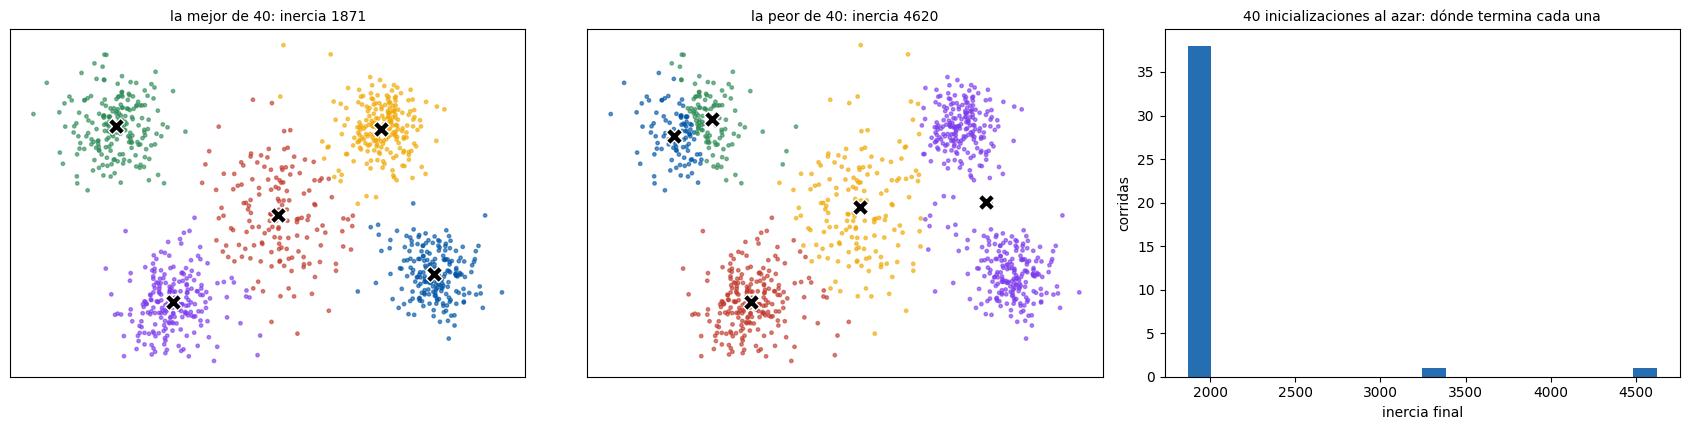

Nubes construidas, k = 5, inicialización al azar: inercia entre 1871 y 4620 (2.5 veces) · 2 de 40 corridas terminan más de un 5 % arriba de la mejor
Agentes, k = 3, inicialización al azar: inercia entre 3395 y 3506 · 2 de 40 corridas terminan más de un 1 % arriba de la mejor


In [5]:
corridas = [KMeans(n_clusters=5, init="random", n_init=1, random_state=s).fit(X_nubes) for s in range(40)]
inercias = np.array([m.inertia_ for m in corridas]); mejor, peor = corridas[int(np.argmin(inercias))], corridas[int(np.argmax(inercias))]
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, m, nombre in [(ejes[0], mejor, "la mejor de 40"), (ejes[1], peor, "la peor de 40")]:
    ax.scatter(X_nubes[:, 0], X_nubes[:, 1], c=[COLORES[e] for e in m.labels_], s=6, alpha=0.6); ax.scatter(m.cluster_centers_[:, 0], m.cluster_centers_[:, 1], marker="X", s=140, c="black", edgecolor="white", zorder=5)
    ax.set_title(f"{nombre}: inercia {m.inertia_:.0f}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
ejes[2].hist(inercias, bins=20, color=AZUL, alpha=0.85); ejes[2].set_xlabel("inercia final"); ejes[2].set_ylabel("corridas"); ejes[2].set_title("40 inicializaciones al azar: dónde termina cada una", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Nubes construidas, k = 5, inicialización al azar: inercia entre {inercias.min():.0f} y {inercias.max():.0f} ({inercias.max() / inercias.min():.1f} veces) · {int((inercias > inercias.min() * 1.05).sum())} de 40 corridas terminan más de un 5 % arriba de la mejor")
inercias_agentes = np.array([KMeans(n_clusters=3, init="random", n_init=1, random_state=s).fit(Z).inertia_ for s in range(40)])
print(f"Agentes, k = 3, inicialización al azar: inercia entre {inercias_agentes.min():.0f} y {inercias_agentes.max():.0f} · {int((inercias_agentes > inercias_agentes.min() * 1.01).sum())} de 40 corridas terminan más de un 1 % arriba de la mejor")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.3 · k-means++</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La inicialización de la diapositiva, a mano y contra el azar, sobre las nubes construidas.</p></div>

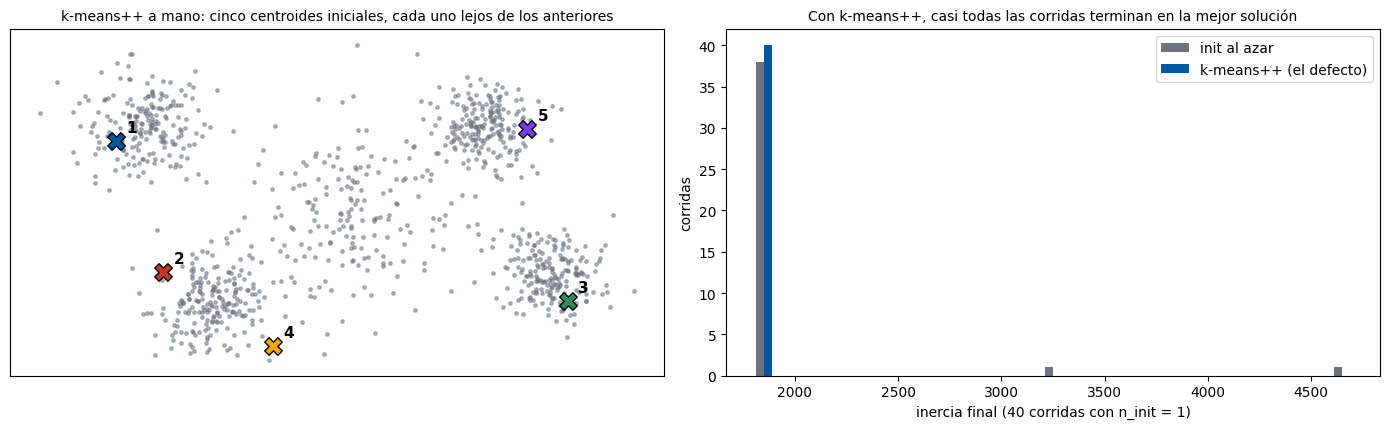

k-means++: 40 de 40 corridas terminan a menos del 1 % de la mejor · al azar: 38 de 40


In [6]:
def kmeans_mas_mas(X, k, rng):
    """k-means++: el primero uniforme; los siguientes con probabilidad proporcional a D(x)²."""
    centroides = [X[rng.integers(len(X))]]
    for _ in range(k - 1):
        D2 = np.min(np.linalg.norm(X[:, None, :] - np.array(centroides)[None, :, :], axis=2), axis=1) ** 2
        centroides.append(X[rng.choice(len(X), p=D2 / D2.sum())])
    return np.array(centroides)
rng = np.random.default_rng(2026); iniciales = kmeans_mas_mas(X_nubes, 5, rng)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4.4))
a.scatter(X_nubes[:, 0], X_nubes[:, 1], s=6, color=GRIS, alpha=0.5)
for j, c_ in enumerate(iniciales): a.scatter(c_[0], c_[1], marker="X", s=160, c=COLORES[j], edgecolor="black", zorder=5); a.text(c_[0] + 0.3, c_[1] + 0.3, str(j + 1), fontsize=11, fontweight="bold")
a.set_title("k-means++ a mano: cinco centroides iniciales, cada uno lejos de los anteriores", fontsize=10); a.set_xticks([]); a.set_yticks([])
inercias_pp = np.array([KMeans(n_clusters=5, init="k-means++", n_init=1, random_state=s).fit(X_nubes).inertia_ for s in range(40)])
b.hist([inercias, inercias_pp], bins=np.linspace(1800, 4700, 30), color=[GRIS, AZUL], label=["init al azar", "k-means++ (el defecto)"])
b.set_xlabel("inercia final (40 corridas con n_init = 1)"); b.set_ylabel("corridas"); b.legend(); b.set_title("Con k-means++, casi todas las corridas terminan en la mejor solución", fontsize=10)
plt.tight_layout(); plt.show()
print(f"k-means++: {int((inercias_pp <= inercias.min() * 1.01).sum())} de 40 corridas terminan a menos del 1 % de la mejor · al azar: {int((inercias <= inercias.min() * 1.01).sum())} de 40")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">A.4 · La sentencia, sobre los agentes</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">KMeans(n_clusters=3, n_init=10).fit(Z)</code>: k-means++, diez corridas, la mejor. Los centroides se devuelven a las unidades originales con el escalador; <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">transform</code> da la distancia a cada centroide. Y las tablas cruzadas con la tarifa y el tipo de agente, que el algoritmo no vio. Por qué 3: B.2.</p></div>

In [7]:
km = KMeans(n_clusters=3, n_init=10, random_state=2026).fit(Z)
print(f"Inercia {km.inertia_:.1f} · iteraciones hasta converger: {km.n_iter_} · tamaños de los grupos: {np.bincount(km.labels_).tolist()}")
centros = pd.DataFrame(escalador.inverse_transform(km.cluster_centers_), columns=COLUMNAS, index=[f"grupo {j}" for j in range(3)])
centros_legibles = centros.assign(**{"demanda media (MWh/mes)": 10 ** centros["log_tamano"], "verano / invierno": 2 ** centros["estacionalidad"], "crecimiento anual (%)": (10 ** centros["tendencia_anual"] - 1) * 100})
print("Los centroides, en las unidades originales (y traducidos):"); display(centros_legibles.round(3))
print("Los grupos contra la tarifa y contra el tipo de agente (que el algoritmo no vio):")
display(pd.concat([pd.crosstab(pd.Series(km.labels_, name="grupo", index=perfiles.index), tarifa), pd.crosstab(pd.Series(km.labels_, name="grupo", index=perfiles.index), etiquetas_reales["categoria_demanda"])], axis=1))
distancias = pd.DataFrame(km.transform(Z[:5]), columns=[f"distancia al grupo {j}" for j in range(3)], index=perfiles.index[:5]).round(2); distancias["grupo"] = km.labels_[:5]
print("transform: la distancia de las cinco primeras series a cada centroide (seis columnas → tres); el grupo es el mínimo:"); display(distancias)

Inercia 3397.3 · iteraciones hasta converger: 8 · tamaños de los grupos: [539, 45, 284]
Los centroides, en las unidades originales (y traducidos):


,log_tamano,estacionalidad,volatilidad,tendencia_anual,frac_caidas,cv,demanda media (MWh/mes),verano / invierno,crecimiento anual (%)
grupo 0,3.545,0.050,0.070,-0.004,0.075,0.152,3509.510,1.035,-0.914
grupo 1,2.830,0.738,0.307,-0.079,0.326,0.837,676.824,1.668,-16.567
grupo 2,2.661,-0.160,0.145,0.060,0.210,0.375,458.641,0.895,14.938


Los grupos contra la tarifa y contra el tipo de agente (que el algoritmo no vio):


,Comercial,Industrial/Comercial Grande,Residencial,Distribuidor,Gran Usuario
grupo,,,,,
0,69,364,106,219,320
1,1,30,14,23,22
2,5,132,147,165,119


transform: la distancia de las cinco primeras series a cada centroide (seis columnas → tres); el grupo es el mínimo:


,distancia al grupo 0,distancia al grupo 1,distancia al grupo 2,grupo
serie,,,,
AARGTAOY | GUMAS/AUTOGENERADORES,0.74,4.86,2.24,0
ABRILHCY | GUMAS/AUTOGENERADORES,0.82,4.70,1.74,0
ACARQQ3Y | GUMAS/AUTOGENERADORES,2.69,3.84,1.33,2
ACARSLSY | GUMAS/AUTOGENERADORES,2.76,3.76,1.33,2
ACERBR1Y | GUMAS/AUTOGENERADORES,1.24,5.75,2.70,0


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Tres comportamientos que se leen: un grupo grande de agentes <b>grandes y estables</b> (pocas caídas, poca variabilidad); un grupo chico, de 45 series, <b>muy variables y de verano</b>: en verano consumen dos tercios más que en invierno, caen fuerte uno de cada tres meses y, en conjunto, vienen en baja; y un tercero de agentes <b>chicos, algo más de invierno y en crecimiento</b>. Los grupos cruzan las tarifas y los tipos de agente: el algoritmo encontró algo que las etiquetas del CSV no dicen. En F se les pone nombre.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">B · Cuántos grupos: minilotes, codo, silueta, límites</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.1 · Más rápido, y por lotes</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Lloyd, Elkan y minilotes sobre 200 000 puntos construidos (igual que en la cátedra) y sobre los perfiles, con k = 8.</p></div>

In [8]:
X_grande, _ = make_blobs(n_samples=200_000, centers=8, n_features=7, cluster_std=1.5, random_state=2026)     # construidos, solo para medir tiempo
filas = []
for nombre, modelo in [("k-medias (lloyd)", KMeans(n_clusters=8, n_init=3, algorithm="lloyd", random_state=2026)), ("k-medias (elkan)", KMeans(n_clusters=8, n_init=3, algorithm="elkan", random_state=2026)), ("minilotes (1024 por lote)", MiniBatchKMeans(n_clusters=8, n_init=3, batch_size=1024, random_state=2026))]:
    t0 = time.perf_counter(); modelo.fit(X_grande); t_g = time.perf_counter() - t0
    t0 = time.perf_counter(); m_s = modelo.__class__(**modelo.get_params()).fit(Z); t_s = time.perf_counter() - t0
    filas.append({"variante": nombre, "200 000 puntos: segundos": t_g, "inercia": modelo.inertia_, "agentes (868, k = 8): ms": t_s * 1000, "inercia agentes": m_s.inertia_})
display(pd.DataFrame(filas).round(2))

,variante,200 000 puntos: segundos,inercia,"agentes (868, k = 8): ms",inercia agentes
0,k-medias (lloyd),0.41,3147032.80,8.44,2019.01
1,k-medias (elkan),0.48,3147032.80,35.44,2019.01
2,minilotes (1024 por lote),0.09,3148344.77,15.27,2078.30


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.2 · La inercia siempre baja: el codo y la silueta</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Para k de 2 a 10, la inercia y la silueta, sobre las nubes construidas (k = 5 evidente) y sobre los agentes.</p></div>

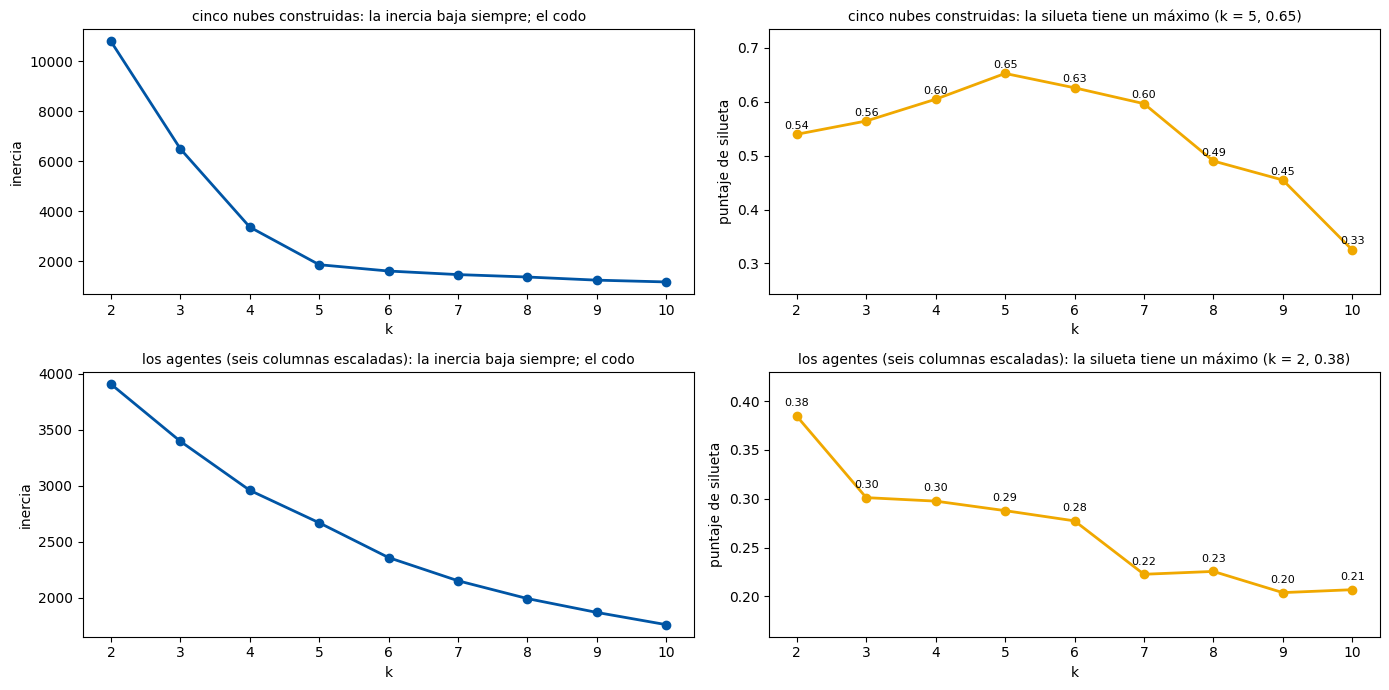

Agentes · inercia por k: 2: 3909 · 3: 3397 · 4: 2959 · 5: 2668 · 6: 2357 · 7: 2150 · 8: 1990 · 9: 1866 · 10: 1757
Agentes · silueta por k: 2: 0.384 · 3: 0.301 · 4: 0.297 · 5: 0.288 · 6: 0.277 · 7: 0.223 · 8: 0.226 · 9: 0.204 · 10: 0.207
Agentes · tamaño del grupo más chico por k: 2: 231 · 3: 45 · 4: 25 · 5: 18 · 6: 14 · 7: 9 · 8: 9 · 9: 9 · 10: 9


In [9]:
ks = range(2, 11)
def codo_y_silueta(X):
    modelos = [KMeans(n_clusters=k, n_init=10, random_state=2026).fit(X) for k in ks]
    return [m.inertia_ for m in modelos], [silhouette_score(X, m.labels_) for m in modelos], [np.bincount(m.labels_).min() for m in modelos]
in_n, si_n, _ = codo_y_silueta(X_nubes); in_s, si_s, min_s = codo_y_silueta(Z)
fig, ejes = plt.subplots(2, 2, figsize=(14, 7))
for fila, (inercias_k, siluetas_k, nombre) in enumerate([(in_n, si_n, "cinco nubes construidas"), (in_s, si_s, "los agentes (seis columnas escaladas)")]):
    a, b = ejes[fila]
    a.plot(list(ks), inercias_k, marker="o", color=AZUL, lw=2); a.set_xlabel("k"); a.set_ylabel("inercia"); a.set_title(f"{nombre}: la inercia baja siempre; el codo", fontsize=10)
    b.plot(list(ks), siluetas_k, marker="o", color=AMBAR, lw=2); b.set_xlabel("k"); b.set_ylabel("puntaje de silueta"); b.margins(y=0.25)
    b.set_title(f"{nombre}: la silueta tiene un máximo (k = {list(ks)[int(np.argmax(siluetas_k))]}, {max(siluetas_k):.2f})", fontsize=10)
    for k_, s_ in zip(ks, siluetas_k): b.text(k_, s_ + 0.01, f"{s_:.2f}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()
print("Agentes · inercia por k: " + " · ".join(f"{k}: {v:.0f}" for k, v in zip(ks, in_s)))
print("Agentes · silueta por k: " + " · ".join(f"{k}: {v:.3f}" for k, v in zip(ks, si_s)))
print("Agentes · tamaño del grupo más chico por k: " + " · ".join(f"{k}: {v}" for k, v in zip(ks, min_s)))

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">En las nubes construidas el máximo es evidente. En los agentes, la silueta es máxima con k = 2 y baja despacio después: hay estructura (bastante más que en los socios del gimnasio), pero no islas. Con k = 2 los grupos son «estables» contra «variables»; con k = 3 la parte variable se divide en dos comportamientos distintos (muy volátiles y de verano, contra de invierno y en crecimiento) que vale la pena distinguir. Con k grande aparecen grupos de un puñado de agentes: los extremos se quedan con un centroide para ellos. El cuaderno elige 3, como decisión y por lo que significan los grupos (F).</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.3 · El diagrama de silueta</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Un coeficiente por instancia: las nubes con k = 3 y k = 5, y los agentes con k = 3.</p></div>

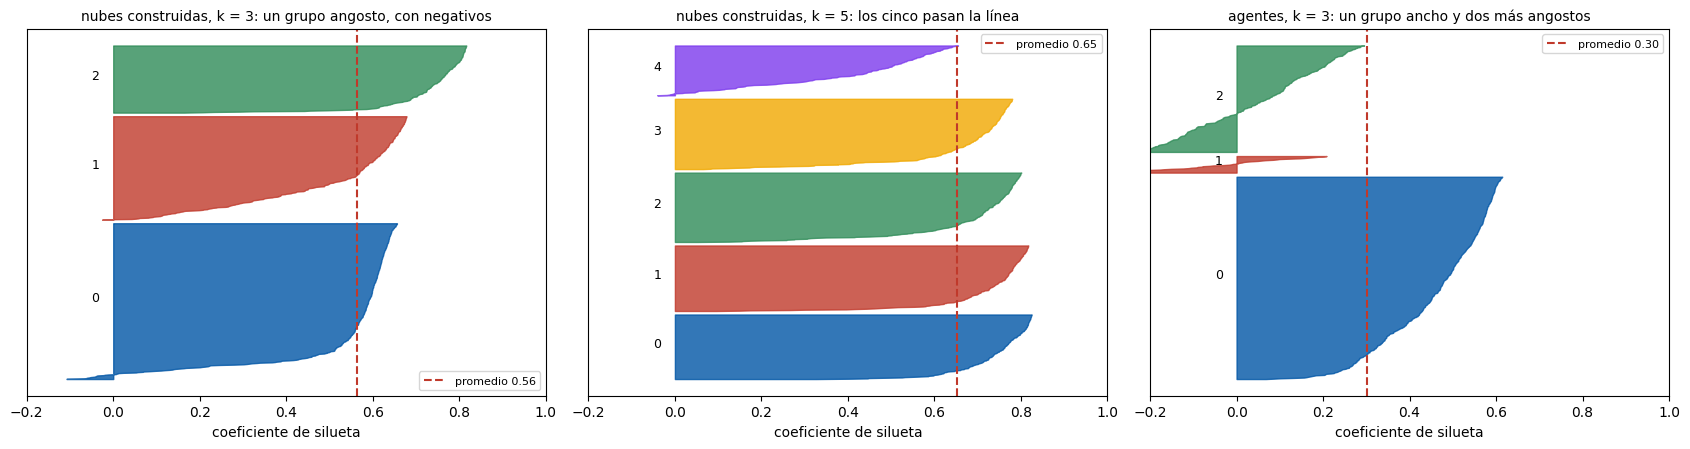

Agentes, k = 3: coeficiente negativo (quizá en el grupo equivocado) en 126 de 868 series · silueta media por grupo: grupo 0 0.46 · grupo 1 -0.03 · grupo 2 0.05


In [10]:
def diagrama_silueta(ax, X, etiquetas, titulo):
    valores = silhouette_samples(X, etiquetas); k_ = etiquetas.max() + 1; y0 = 10
    for j in range(k_):
        v = np.sort(valores[etiquetas == j]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COLORES[j], alpha=0.8); ax.text(-0.05, y0 + len(v) / 2, str(j), fontsize=9); y0 += len(v) + 10
    ax.axvline(valores.mean(), color=ROJO, ls="--", label=f"promedio {valores.mean():.2f}"); ax.set_xlabel("coeficiente de silueta"); ax.set_yticks([]); ax.set_xlim(-0.2, 1); ax.legend(fontsize=8); ax.set_title(titulo, fontsize=10)
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.6))
diagrama_silueta(ejes[0], X_nubes, KMeans(n_clusters=3, n_init=10, random_state=2026).fit(X_nubes).labels_, "nubes construidas, k = 3: un grupo angosto, con negativos")
diagrama_silueta(ejes[1], X_nubes, KMeans(n_clusters=5, n_init=10, random_state=2026).fit(X_nubes).labels_, "nubes construidas, k = 5: los cinco pasan la línea")
diagrama_silueta(ejes[2], Z, km.labels_, "agentes, k = 3: un grupo ancho y dos más angostos")
plt.tight_layout(); plt.show()
coef_ag = silhouette_samples(Z, km.labels_)
print(f"Agentes, k = 3: coeficiente negativo (quizá en el grupo equivocado) en {int((coef_ag < 0).sum())} de {len(Z)} series · silueta media por grupo: " + " · ".join(f"grupo {j} {coef_ag[km.labels_ == j].mean():.2f}" for j in range(3)))

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Acá está el matiz de estos datos: el grupo de los grandes y estables tiene una silueta media alta (~0,46), pero los otros dos rondan el cero. Son agentes que se parecen más a «no ser estables» que entre sí: el centroide los describe en promedio, no uno por uno. Unas 120 series tienen coeficiente negativo.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.4 · Límites: las tres geometrías</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Nubes, elipses y lunas construidas, como en la cátedra.</p></div>

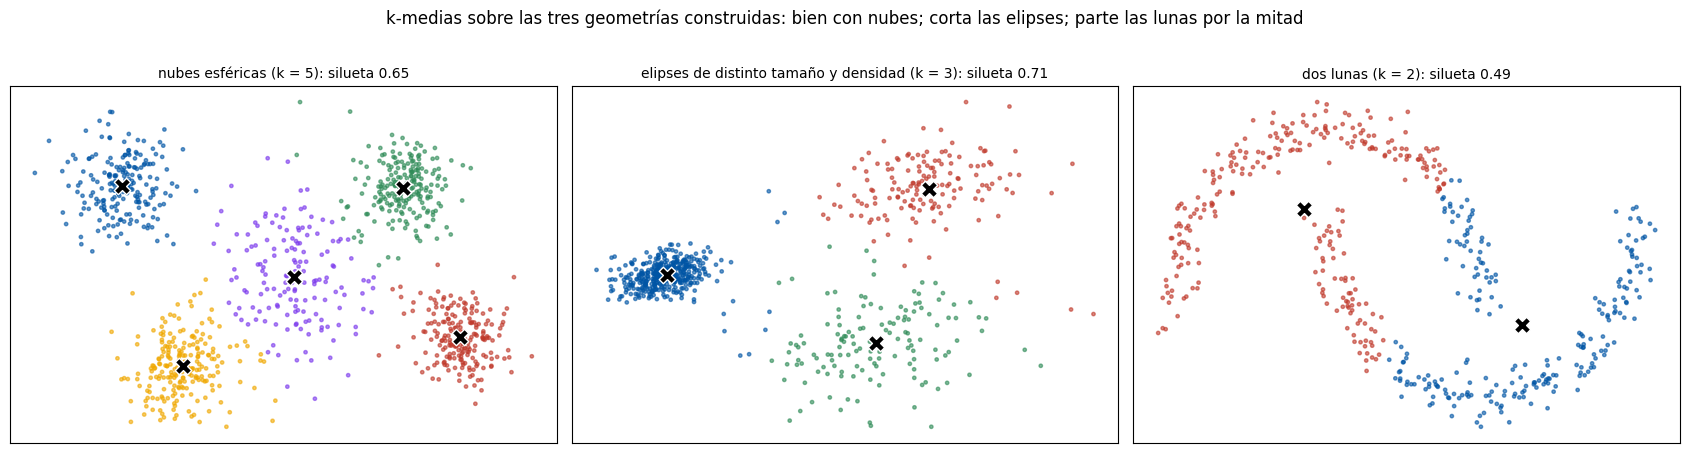

In [11]:
X_el, _ = make_blobs(n_samples=[400, 150, 150], centers=[[0, 0], [5, 4], [6, -3]], cluster_std=[0.5, 1.0, 1.5], random_state=2026)
X_el = np.c_[X_el[:, 0] * 2.2 + X_el[:, 1] * 0.6, X_el[:, 1]]                   # estiradas e inclinadas
X_lu, _ = make_moons(n_samples=500, noise=0.07, random_state=2026)
geometrias = [("nubes esféricas (k = 5)", X_nubes, 5), ("elipses de distinto tamaño y densidad (k = 3)", X_el, 3), ("dos lunas (k = 2)", X_lu, 2)]
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, (nombre, Xg, kg) in zip(ejes, geometrias):
    m = KMeans(n_clusters=kg, n_init=10, random_state=2026).fit(Xg)
    ax.scatter(Xg[:, 0], Xg[:, 1], c=[COLORES[e] for e in m.labels_], s=6, alpha=0.6); ax.scatter(m.cluster_centers_[:, 0], m.cluster_centers_[:, 1], marker="X", s=140, c="black", edgecolor="white", zorder=5)
    ax.set_title(f"{nombre}: silueta {silhouette_score(Xg, m.labels_):.2f}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("k-medias sobre las tres geometrías construidas: bien con nubes; corta las elipses; parte las lunas por la mitad", y=1.02)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">B.5 · Sin escalar, decide la columna de mayor rango</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">El mismo k-medias con k = 3 sobre las seis columnas sin escalar: el tamaño (en log, con un desvío de ~0,9) y la estacionalidad (~0,4) pesan mucho más que la volatilidad (~0,09). Y un caso más extremo: el tamaño en MWh en vez de en log.</p></div>

In [12]:
km_crudo = KMeans(n_clusters=3, n_init=10, random_state=2026).fit(perfiles[COLUMNAS])
print("Desvío de cada columna sin escalar (lo que pesa en la distancia): " + " · ".join(f"{c_} {perfiles[c_].std():.3f}" for c_ in COLUMNAS))
print(f"Sin escalar · tamaños {np.bincount(km_crudo.labels_).tolist()} · Rand ajustado contra el escalado: {adjusted_rand_score(km.labels_, km_crudo.labels_):.2f}")
print("Los centroides sin escalar (casi solo cambia el tamaño):"); display(pd.DataFrame(km_crudo.cluster_centers_, columns=COLUMNAS).round(3))
en_mwh = perfiles[COLUMNAS].assign(log_tamano=10 ** perfiles["log_tamano"]).rename(columns={"log_tamano": "demanda media (MWh)"})
km_mwh = KMeans(n_clusters=3, n_init=10, random_state=2026).fit(en_mwh)
print(f"Con el tamaño en MWh y sin escalar · tamaños {np.bincount(km_mwh.labels_).tolist()}: un grupo con casi todos y dos con las pocas distribuidoras gigantes; las otras cinco columnas no cuentan")

Desvío de cada columna sin escalar (lo que pesa en la distancia): log_tamano 0.921 · estacionalidad 0.406 · volatilidad 0.086 · tendencia_anual 0.157 · frac_caidas 0.103 · cv 0.225
Sin escalar · tamaños [532, 248, 88] · Rand ajustado contra el escalado: 0.07
Los centroides sin escalar (casi solo cambia el tamaño):


,log_tamano,estacionalidad,volatilidad,tendencia_anual,frac_caidas,cv
0,3.046,0.033,0.110,-0.013,0.138,0.251
1,4.241,0.005,0.086,0.022,0.104,0.190
2,1.385,-0.045,0.147,0.151,0.176,0.517


Con el tamaño en MWh y sin escalar · tamaños [829, 4, 35]: un grupo con casi todos y dos con las pocas distribuidoras gigantes; las otras cinco columnas no cuentan


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">C · Fusionar: el aglomerativo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.1 · La sentencia: AgglomerativeClustering</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">AgglomerativeClustering(n_clusters=3, linkage="ward")</code> sobre los agentes, contra k-medias: tamaños, tabla cruzada, Rand ajustado y silueta.</p></div>

In [13]:
ward = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(Z)
print(f"Ward con 3 grupos · tamaños {np.bincount(ward.labels_).tolist()} · silueta {silhouette_score(Z, ward.labels_):.3f} (k-medias: {silhouette_score(Z, km.labels_):.3f}) · índice de Rand ajustado contra k-medias: {adjusted_rand_score(km.labels_, ward.labels_):.2f}")
print("Los grupos de Ward contra los de k-medias:"); display(pd.crosstab(pd.Series(ward.labels_, name="Ward"), pd.Series(km.labels_, name="k-medias")))
print(f"Fusiones hechas: {len(ward.children_)} (de {len(Z)} grupos de una serie a {ward.n_clusters_})")

Ward con 3 grupos · tamaños [74, 338, 456] · silueta 0.178 (k-medias: 0.301) · índice de Rand ajustado contra k-medias: 0.25
Los grupos de Ward contra los de k-medias:


k-medias,0,1,2
Ward,,,
0,0,16,58
1,336,0,2
2,203,29,224


Fusiones hechas: 867 (de 868 grupos de una serie a 3)


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.2 · Tres enlaces, dos lunas</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">La figura de la diapositiva con las lunas y las elipses construidas, igual que en la cátedra.</p></div>

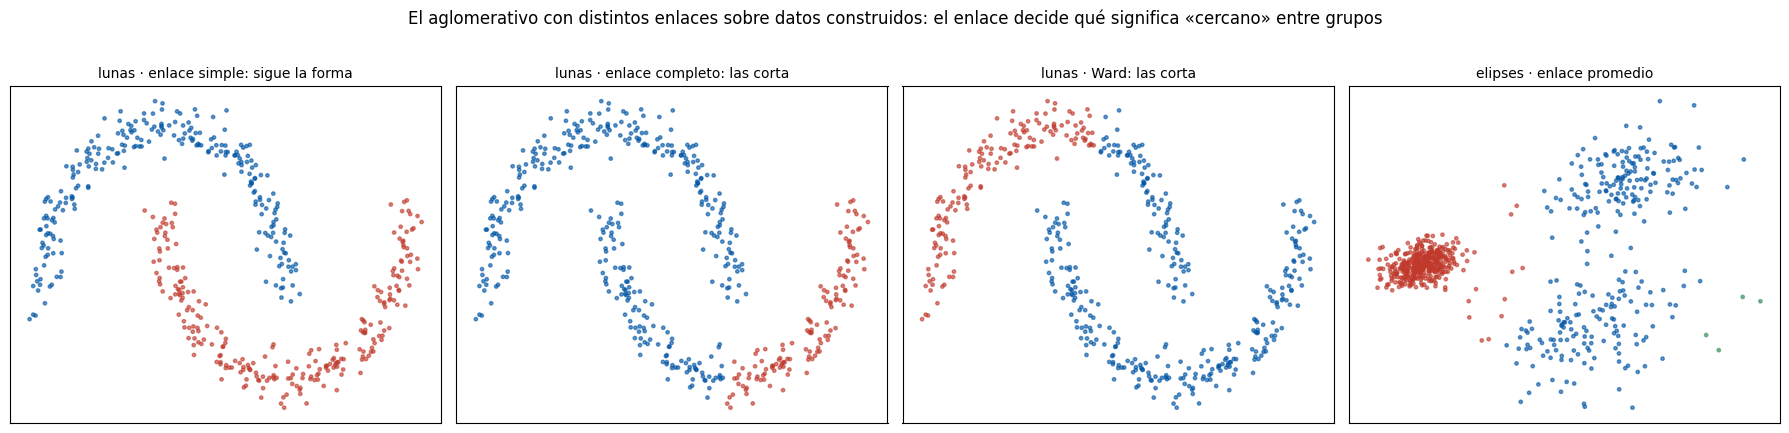

In [14]:
fig, ejes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (Xg, enlace, nombre) in zip(ejes, [(X_lu, "single", "lunas · enlace simple: sigue la forma"), (X_lu, "complete", "lunas · enlace completo: las corta"), (X_lu, "ward", "lunas · Ward: las corta"), (X_el, "average", "elipses · enlace promedio")]):
    etiquetas = AgglomerativeClustering(n_clusters=2 if Xg is X_lu else 3, linkage=enlace).fit_predict(Xg)
    ax.scatter(Xg[:, 0], Xg[:, 1], c=[COLORES[e] for e in etiquetas], s=6, alpha=0.6); ax.set_title(nombre, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("El aglomerativo con distintos enlaces sobre datos construidos: el enlace decide qué significa «cercano» entre grupos", y=1.02)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.3 · El dendrograma</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Treinta series al azar y su dendrograma con Ward, rotuladas con el nombre del agente.</p></div>

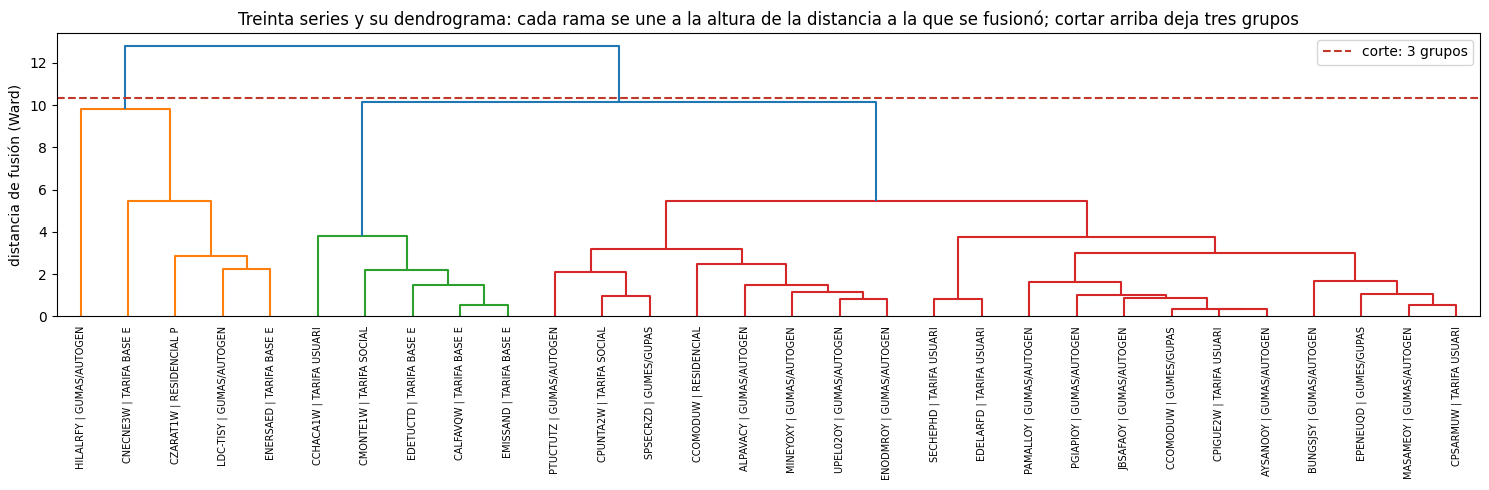

Las últimas cinco fusiones ocurrieron a distancias [5.5, 5.5, 9.8, 10.1, 12.8] · el salto más grande deja 4 grupos · con fcluster, cortando en 3: tamaños [5, 5, 20]


In [15]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

rng = np.random.default_rng(2026); muestra = rng.choice(len(Z), 30, replace=False)
enlaces = linkage(Z[muestra], method="ward")
fig, ax = plt.subplots(figsize=(15, 5))
dendrogram(enlaces, labels=[perfiles.index[i][:24] for i in muestra], leaf_font_size=7, leaf_rotation=90, color_threshold=enlaces[-2, 2], ax=ax)
ax.axhline(enlaces[-2, 2] * 1.02, color=ROJO, ls="--", label="corte: 3 grupos"); ax.set_ylabel("distancia de fusión (Ward)"); ax.legend()
ax.set_title("Treinta series y su dendrograma: cada rama se une a la altura de la distancia a la que se fusionó; cortar arriba deja tres grupos")
plt.tight_layout(); plt.show()
saltos = np.diff(enlaces[:, 2]); k_sugerido = len(enlaces) + 1 - (int(np.argmax(saltos)) + 1)
print(f"Las últimas cinco fusiones ocurrieron a distancias {enlaces[-5:, 2].round(1).tolist()} · el salto más grande deja {k_sugerido} grupos · con fcluster, cortando en 3: tamaños {np.bincount(fcluster(enlaces, 3, criterion='maxclust')).tolist()[1:]}")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">C.4 · La métrica</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Enlace promedio con distancia euclidiana, Manhattan y coseno sobre los agentes, contra Ward.</p></div>

In [16]:
filas = []
for metrica in ["euclidean", "manhattan", "cosine"]:
    etiquetas = AgglomerativeClustering(n_clusters=3, linkage="average", metric=metrica).fit_predict(Z)
    filas.append({"métrica": metrica, "enlace": "promedio", "tamaños": np.bincount(etiquetas).tolist(), "silueta (misma métrica)": silhouette_score(Z, etiquetas, metric=metrica)})
filas.append({"métrica": "euclidean", "enlace": "ward", "tamaños": np.bincount(ward.labels_).tolist(), "silueta (misma métrica)": silhouette_score(Z, ward.labels_)})
display(pd.DataFrame(filas).round(3))
print("El enlace promedio tiende a dejar un grupo gigante y grupos de unos pocos agentes extremos (el «rich get richer» de la guía de scikit-learn); Ward reparte. La silueta no es comparable entre métricas distintas: mide en geometrías distintas.")

,métrica,enlace,tamaños,silueta (misma métrica)
0,euclidean,promedio,"[860, 7, 1]",0.695
1,manhattan,promedio,"[864, 3, 1]",0.711
2,cosine,promedio,"[342, 132, 394]",0.359
3,euclidean,ward,"[74, 338, 456]",0.178


El enlace promedio tiende a dejar un grupo gigante y grupos de unos pocos agentes extremos (el «rich get richer» de la guía de scikit-learn); Ward reparte. La silueta no es comparable entre métricas distintas: mide en geometrías distintas.


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con enlace promedio y distancia euclidiana, los grupos «chicos» son casi siempre un puñado de agentes extremos: el enlace promedio aísla lo raro antes de partir lo común. Con coseno la geometría es otra (importa la dirección del perfil, no su tamaño) y los grupos cambian. Ward reparte, pero en el grupo de los no estables corta distinto que k-medias.</p></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">D · Dividir: k-medias bisectivo</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">D.1 · Partir en dos, hasta k</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">BisectingKMeans</code> sobre las nubes construidas (como en la cátedra) y sobre los agentes, con las dos estrategias.</p></div>

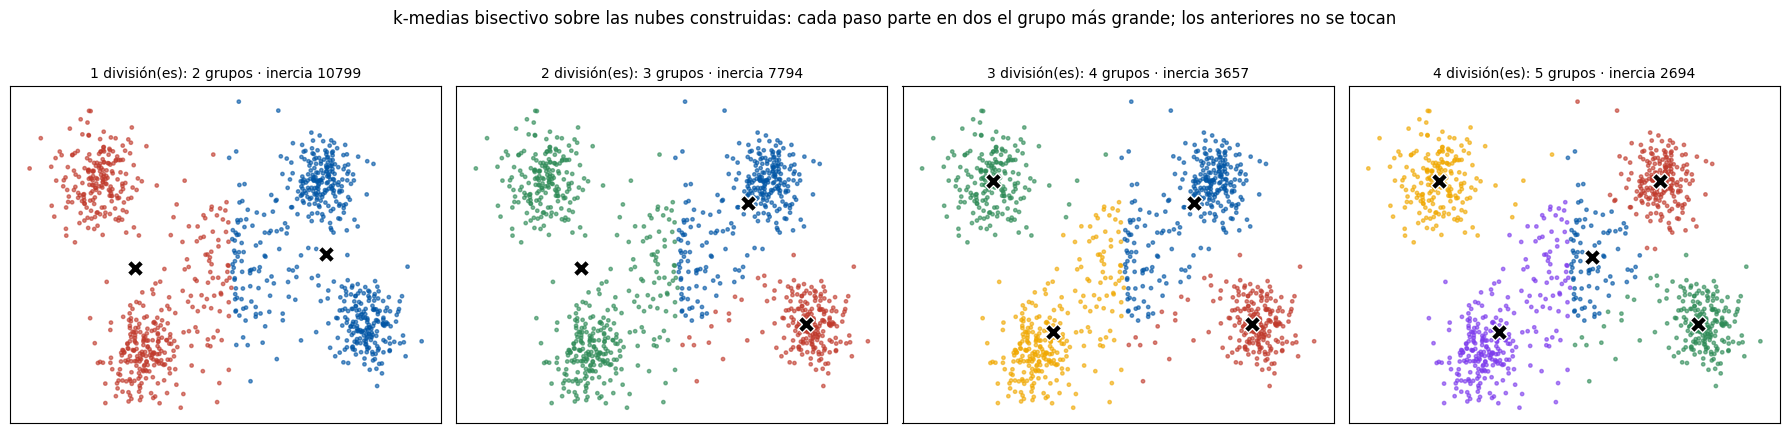

,estrategia,tamaños,inercia,silueta,Rand ajustado contra k-medias,ms
0,largest_cluster,"[295, 355, 218]",3598.165,0.144,0.399,8.018
1,biggest_inertia,"[650, 27, 191]",3455.639,0.363,0.558,10.667
2,k-medias (referencia),"[539, 45, 284]",3397.316,0.301,1.000,NaN


In [17]:
fig, ejes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, kb in zip(ejes, [2, 3, 4, 5]):
    bk = BisectingKMeans(n_clusters=kb, bisecting_strategy="largest_cluster", random_state=2026).fit(X_nubes)
    ax.scatter(X_nubes[:, 0], X_nubes[:, 1], c=[COLORES[e] for e in bk.labels_], s=6, alpha=0.6); ax.scatter(bk.cluster_centers_[:, 0], bk.cluster_centers_[:, 1], marker="X", s=140, c="black", edgecolor="white", zorder=5)
    ax.set_title(f"{kb - 1} división(es): {kb} grupos · inercia {bk.inertia_:.0f}", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("k-medias bisectivo sobre las nubes construidas: cada paso parte en dos el grupo más grande; los anteriores no se tocan", y=1.02)
plt.tight_layout(); plt.show()
filas = []
for estrategia in ["largest_cluster", "biggest_inertia"]:
    t0 = time.perf_counter(); bk = BisectingKMeans(n_clusters=3, bisecting_strategy=estrategia, random_state=2026).fit(Z); t_b = (time.perf_counter() - t0) * 1000
    filas.append({"estrategia": estrategia, "tamaños": np.bincount(bk.labels_).tolist(), "inercia": bk.inertia_, "silueta": silhouette_score(Z, bk.labels_), "Rand ajustado contra k-medias": adjusted_rand_score(km.labels_, bk.labels_), "ms": t_b})
filas.append({"estrategia": "k-medias (referencia)", "tamaños": np.bincount(km.labels_).tolist(), "inercia": km.inertia_, "silueta": silhouette_score(Z, km.labels_), "Rand ajustado contra k-medias": 1.0, "ms": np.nan})
display(pd.DataFrame(filas).round(3))

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">E · El comparativo: cuál para qué</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Los cuatro algoritmos sobre los agentes y sobre las tres geometrías</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Sobre los agentes (k = 3): silueta, inercia, tiempo, tamaños y Rand ajustado contra k-medias. Y la grilla de la diapositiva sobre las geometrías construidas.</p></div>

,algoritmo,silueta,inercia,ms,tamaños,Rand ajustado contra k-medias
0,k-medias,0.301,3397.316,30.482,"[539, 45, 284]",1.000
1,minilotes,0.369,3422.152,15.058,"[191, 602, 75]",0.624
2,aglomerativo (Ward),0.178,NaN,19.046,"[74, 338, 456]",0.246
3,bisectivo,0.363,3455.639,4.439,"[650, 27, 191]",0.558


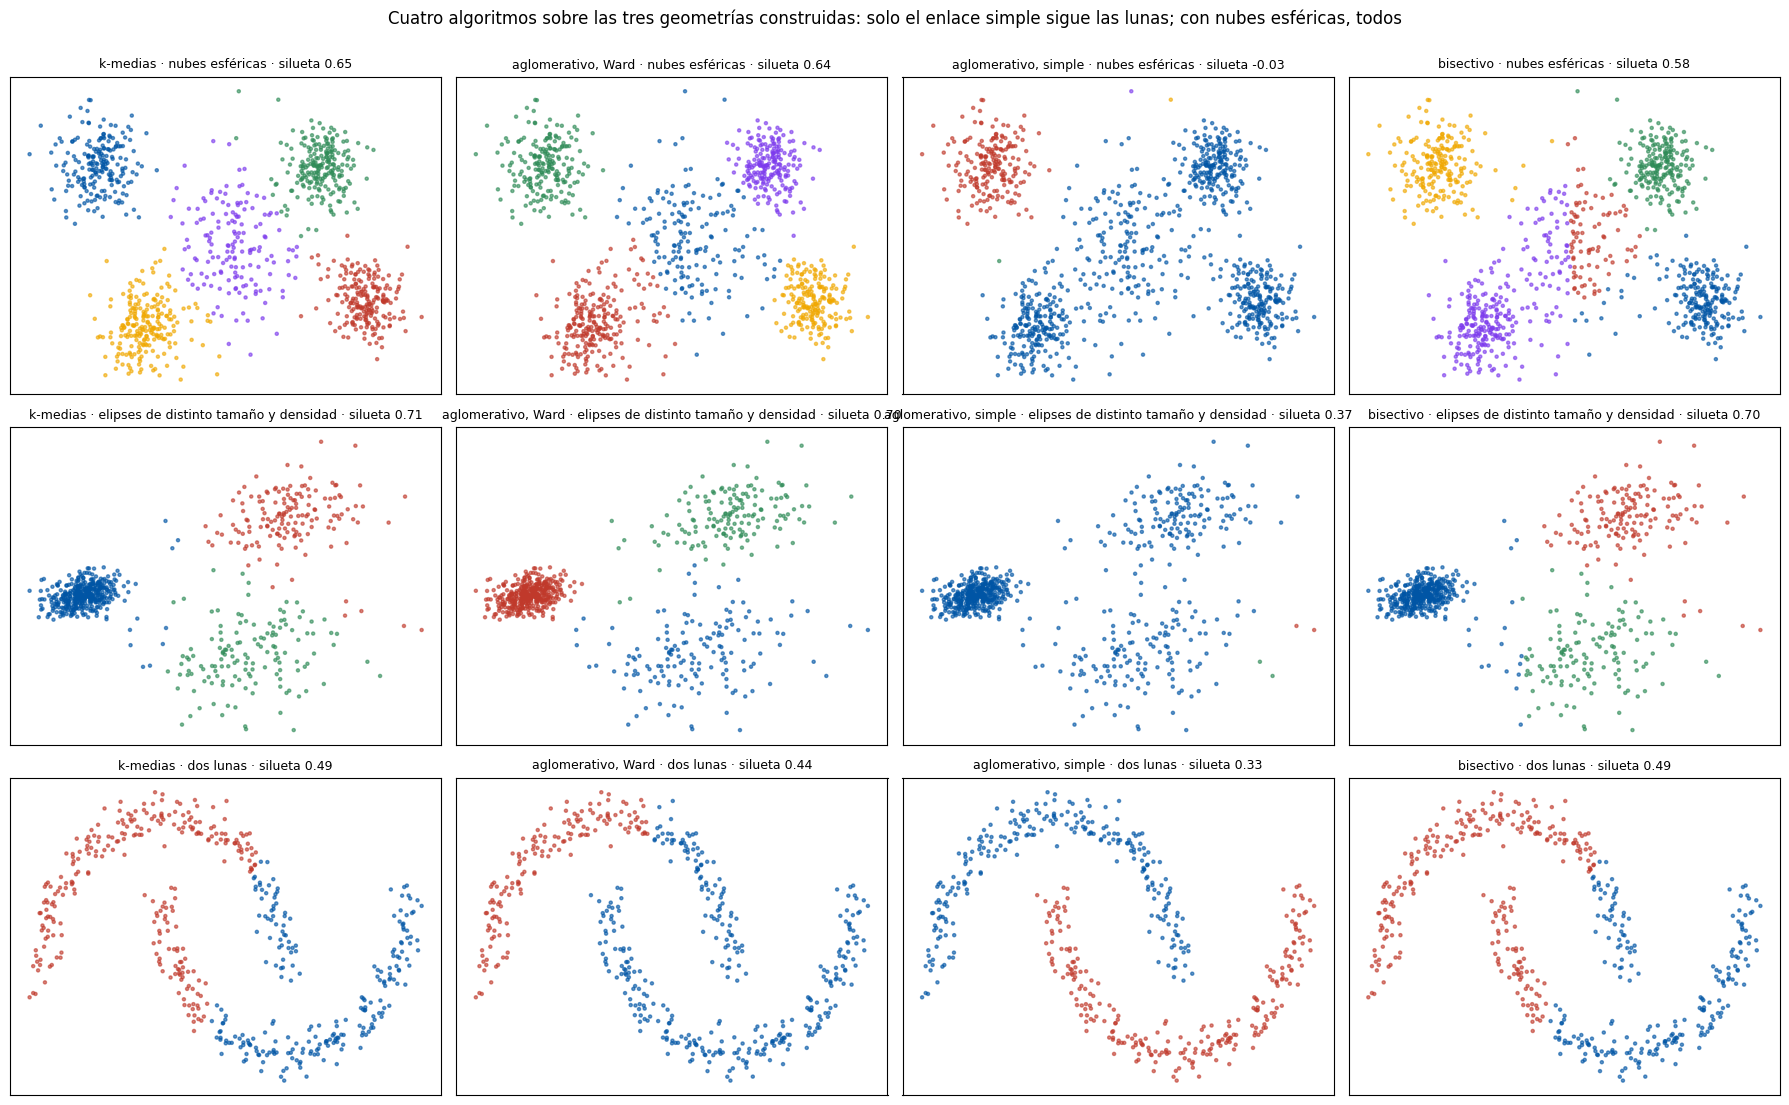

In [18]:
filas = []
for nombre, modelo in [("k-medias", KMeans(n_clusters=3, n_init=10, random_state=2026)), ("minilotes", MiniBatchKMeans(n_clusters=3, n_init=10, random_state=2026)), ("aglomerativo (Ward)", AgglomerativeClustering(n_clusters=3, linkage="ward")), ("bisectivo", BisectingKMeans(n_clusters=3, random_state=2026))]:
    t0 = time.perf_counter(); etiquetas = modelo.fit_predict(Z); t_ = (time.perf_counter() - t0) * 1000
    filas.append({"algoritmo": nombre, "silueta": silhouette_score(Z, etiquetas), "inercia": getattr(modelo, "inertia_", np.nan), "ms": t_, "tamaños": np.bincount(etiquetas).tolist(), "Rand ajustado contra k-medias": adjusted_rand_score(km.labels_, etiquetas)})
display(pd.DataFrame(filas).round(3))
fig, ejes = plt.subplots(3, 4, figsize=(18, 11))
for fila, (nombre_g, Xg, kg) in enumerate(geometrias):
    for col, (nombre_a, hacer) in enumerate([("k-medias", lambda X, k_: KMeans(n_clusters=k_, n_init=10, random_state=2026).fit_predict(X)), ("aglomerativo, Ward", lambda X, k_: AgglomerativeClustering(n_clusters=k_, linkage="ward").fit_predict(X)), ("aglomerativo, simple", lambda X, k_: AgglomerativeClustering(n_clusters=k_, linkage="single").fit_predict(X)), ("bisectivo", lambda X, k_: BisectingKMeans(n_clusters=k_, random_state=2026).fit_predict(X))]):
        etiquetas = hacer(Xg, kg); ax = ejes[fila, col]
        ax.scatter(Xg[:, 0], Xg[:, 1], c=[COLORES[e] for e in etiquetas], s=5, alpha=0.6); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{nombre_a} · {nombre_g.split(' (')[0]} · silueta {silhouette_score(Xg, etiquetas):.2f}", fontsize=9)
fig.suptitle("Cuatro algoritmos sobre las tres geometrías construidas: solo el enlace simple sigue las lunas; con nubes esféricas, todos", y=1.0)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">La elección</b></div><table style="border-collapse: collapse; width: 100%; font-size: 0.96em; margin-top: 4px;"><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Sobre los agentes</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Acá los algoritmos <b>no</b> coinciden tanto como en el gimnasio: el Rand ajustado contra k-medias va de ~0,25 (Ward) a ~0,6 (minilotes), y los tamaños cambian mucho. Lo que se repite en todos es un grupo grande de agentes estables; cómo se parte el resto (los variables, los de invierno, los extremos) depende del algoritmo. El diagrama de silueta ya lo decía: solo el grupo de los grandes y estables tiene silueta alta. Se elige k-medias con k = 3 por lo que los grupos significan (F), sabiendo que con k = 2 la silueta es mejor y que la partición del resto es frágil.</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Sobre las geometrías</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">La regla de la diapositiva: nubes esféricas y k conocido, k-medias; muchas filas, minilotes o bisectivo; k desconocido y pocas filas, el dendrograma; formas irregulares, enlace simple o densidad (la clase que viene).</td></tr><tr><td style="padding: 5px 10px; font-weight: bold; color: #003366; vertical-align: top; width: 22%;">Lo propio de estos datos</td><td style="padding: 5px 10px; color: #222; line-height: 1.5;">Los agentes extremos: con k grande o con enlace promedio se quedan con grupos para ellos solos. Si interesara encontrarlos, eso es justamente lo que hace bien la densidad (la clase que viene), que los deja como ruido.</td></tr></table></div>

<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">F · Usarlo: los grupos de agentes, uno nuevo, diez agentes</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué es cada grupo</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Los tres grupos de k-medias descritos: el centroide traducido, cuántas series, qué tarifas y tipos de agente tienen, y las columnas que más los separan. Los nombres se ponen mirando los centroides: el de mayor tamaño, el de mayor estacionalidad, y el que queda.</p></div>

,nombre,series,demanda media (MWh/mes),verano / invierno,volatilidad,crecimiento anual (%),frac_caidas,cv,tarifa más común,% grandes usuarios
grupo 0,grandes y estables,539,3509.51,1.04,0.07,-0.91,0.07,0.15,Industrial/Comercial Grande,59.37
grupo 1,"muy variables, de verano y en baja",45,676.82,1.67,0.31,-16.57,0.33,0.84,Industrial/Comercial Grande,48.89
grupo 2,"chicos, algo más de invierno y en crecimiento",284,458.64,0.90,0.15,14.94,0.21,0.38,Residencial,41.90


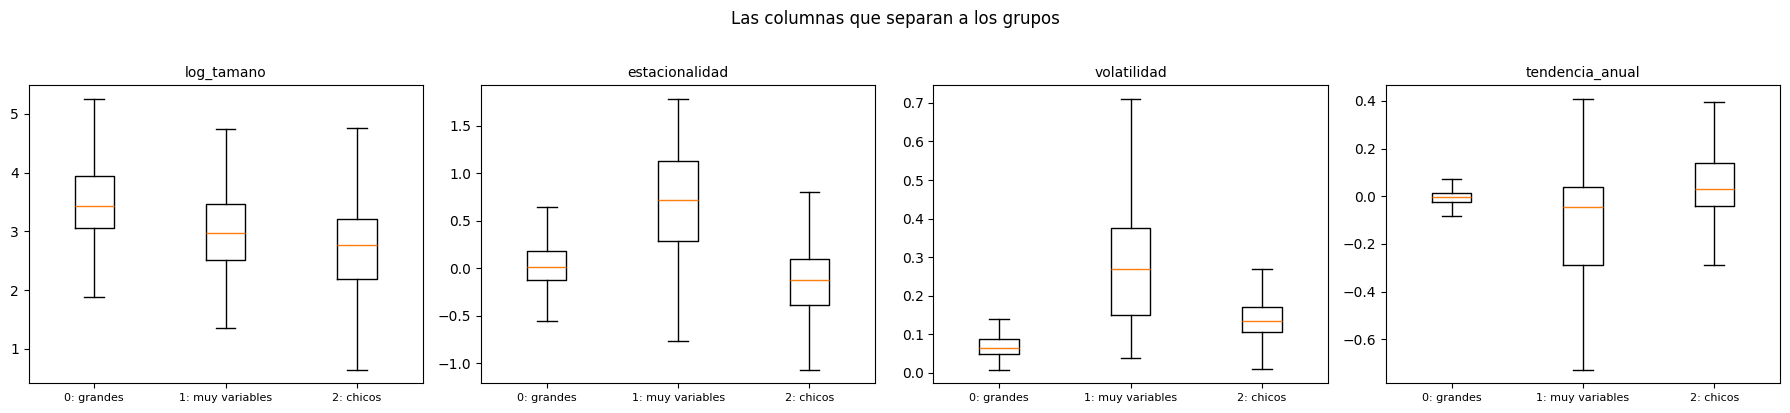

grupo 0: grandes y estables · 539 series
grupo 1: muy variables, de verano y en baja · 45 series
grupo 2: chicos, algo más de invierno y en crecimiento · 284 series


In [19]:
j_grande = int(centros["log_tamano"].idxmax().split()[-1])
resto = [j for j in range(3) if j != j_grande]
j_verano = max(resto, key=lambda j: centros.loc[f"grupo {j}", "estacionalidad"])
j_otro = [j for j in resto if j != j_verano][0]
nombres_grupo = {j_grande: "grandes y estables", j_verano: "muy variables, de verano y en baja", j_otro: "chicos, algo más de invierno y en crecimiento"}
descripcion = centros_legibles[["demanda media (MWh/mes)", "verano / invierno", "volatilidad", "crecimiento anual (%)", "frac_caidas", "cv"]].copy()
descripcion.insert(0, "nombre", [nombres_grupo[j] for j in range(3)])
descripcion.insert(1, "series", np.bincount(km.labels_))
descripcion["tarifa más común"] = [tarifa[km.labels_ == j].mode()[0] for j in range(3)]
descripcion["% grandes usuarios"] = [(etiquetas_reales["categoria_demanda"][km.labels_ == j] == "Gran Usuario").mean() * 100 for j in range(3)]
display(descripcion.round(2))
fig, ejes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(ejes, ["log_tamano", "estacionalidad", "volatilidad", "tendencia_anual"]):
    ax.boxplot([perfiles.loc[km.labels_ == j, col] for j in range(3)], tick_labels=[f"{j}: {nombres_grupo[j].split(',')[0].split(' y ')[0]}" for j in range(3)], showfliers=False)
    ax.set_title(col, fontsize=10); ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Las columnas que separan a los grupos", y=1.02)
plt.tight_layout(); plt.show()
for j in range(3): print(f"grupo {j}: {nombres_grupo[j]} · {np.bincount(km.labels_)[j]} series")

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Las curvas de demanda de cada grupo</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Lo que los seis números resumen, visto en el tiempo: la demanda mensual de cada serie dividida por su propia media (así un agente chico y uno gigante se pueden comparar), con la mediana de cada grupo.</p></div>

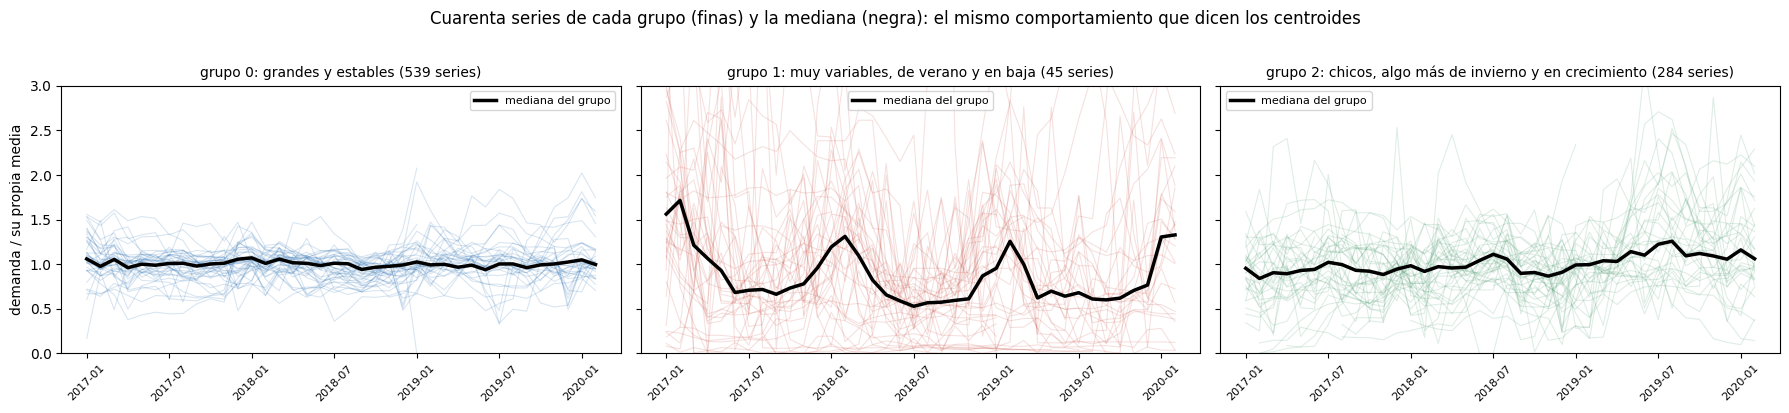

In [20]:
curvas = demanda[demanda["serie"].isin(perfiles.index)].pivot_table(index="serie", columns="periodo", values="demanda_MWh")
curvas = curvas.div(curvas.mean(axis=1), axis=0)
grupo_serie = pd.Series(km.labels_, index=perfiles.index)
fig, ejes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
x = np.arange(curvas.shape[1]); etiquetas_x = [str(p) for p in curvas.columns]
for ax, j in zip(ejes, range(3)):
    sub = curvas.loc[grupo_serie[grupo_serie == j].index]
    for _, fila_c in sub.sample(min(40, len(sub)), random_state=2026).iterrows(): ax.plot(x, fila_c.values, color=COLORES[j], alpha=0.15, lw=0.8)
    ax.plot(x, sub.median().values, color="black", lw=2.5, label="mediana del grupo")
    ax.set_xticks(x[::6]); ax.set_xticklabels(etiquetas_x[::6], rotation=45, fontsize=8); ax.set_ylim(0, 3)
    ax.set_title(f"grupo {j}: {nombres_grupo[j]} ({len(sub)} series)", fontsize=10); ax.legend(fontsize=8)
ejes[0].set_ylabel("demanda / su propia media")
fig.suptitle("Cuarenta series de cada grupo (finas) y la mediana (negra): el mismo comportamiento que dicen los centroides", y=1.02)
plt.tight_layout(); plt.show()

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Las curvas confirman los nombres. Los grandes y estables son casi planos. Los muy variables tienen picos marcados cada diciembre-febrero, curvas individuales que saltan por todos lados y una mediana que va bajando año a año. Los chicos de invierno tienen un leve abultamiento en julio y una tendencia suave a crecer: es el grupo menos definido, y se nota. Esto no lo vio ningún algoritmo: los seis números resumieron razonablemente bien las curvas.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Un agente nuevo, y a qué grupo va</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Un agente inventado con su perfil (por ejemplo, un comercio de unos 800 MWh por mes, que consume 40 % más en verano, con variaciones mensuales de ~12 %, que crece 3 % por año y cae fuerte uno de cada seis meses): se escala con lo aprendido, <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">predict</code> dice el grupo y <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">transform</code> la distancia a cada centroide. Y la silueta que tendría, a mano.</p></div>

In [21]:
nuevo = pd.DataFrame([{"log_tamano": np.log10(800), "estacionalidad": np.log2(1.4), "volatilidad": 0.12, "tendencia_anual": np.log10(1.03), "frac_caidas": 1 / 6, "cv": 0.25}])
z_nuevo = escalador.transform(nuevo[COLUMNAS])
grupo = int(km.predict(z_nuevo)[0]); d = km.transform(z_nuevo)[0]
print(f"Agente nuevo: {nuevo.round(3).iloc[0].to_dict()}")
print(f"Grupo: {grupo} ({nombres_grupo[grupo]}) · distancia a cada centroide: { {g: float(v) for g, v in zip(range(3), d.round(2))} }")
a_ = np.mean(np.linalg.norm(Z[km.labels_ == grupo] - z_nuevo, axis=1)); b_ = min(np.mean(np.linalg.norm(Z[km.labels_ == j] - z_nuevo, axis=1)) for j in range(3) if j != grupo)
print(f"Silueta a mano: a = {a_:.2f} (distancia media a su grupo) · b = {b_:.2f} (al grupo más cercano) · (b − a)/max(a, b) = {(b_ - a_) / max(a_, b_):.2f}")

Agente nuevo: {'log_tamano': 2.903, 'estacionalidad': 0.485, 'volatilidad': 0.12, 'tendencia_anual': 0.013, 'frac_caidas': 0.167, 'cv': 0.25}
Grupo: 0 (grandes y estables) · distancia a cada centroide: {0: 1.72, 1: 3.83, 2: 1.81}
Silueta a mano: a = 2.07 (distancia media a su grupo) · b = 2.67 (al grupo más cercano) · (b − a)/max(a, b) = 0.22


<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Qué se ve</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Con 800 MWh por mes y algo de estacionalidad, el agente queda casi a la misma distancia del centroide de los grandes y estables que del de los chicos de invierno (1,72 contra 1,81): va al primero, pero con una silueta baja. Es un caso de límite, como muchos agentes reales.</p></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span><b style="color: #003366; margin-left: 8px;">Diez agentes, con su grupo y su silueta</b></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;">Diez series que cubren el rango de la silueta, del que está bien adentro de su grupo al que está del lado equivocado, con su perfil, su grupo, su tarifa real, las distancias y el coeficiente.</p></div>

In [22]:
coef = silhouette_samples(Z, km.labels_)
objetivos = np.linspace(coef.max(), coef.min(), 10); elegidos, usados = [], set()
for objetivo in objetivos:
    for candidato in np.argsort(np.abs(coef - objetivo), kind="stable"):
        if candidato not in usados: elegidos.append(candidato); usados.add(candidato); break
elegidos = np.array(elegidos)
explicado = perfiles.iloc[elegidos][COLUMNAS].copy()
explicado.insert(0, "tarifa", tarifa.iloc[elegidos].values)
explicado["grupo"] = km.labels_[elegidos]
for j in range(3): explicado[f"dist. grupo {j}"] = km.transform(Z[elegidos])[:, j].round(2)
explicado["silueta"] = coef[elegidos].round(3)
explicado.index.name = "serie"
(explicado.style.format(precision=2).format({"silueta": "{:.3f}"}).background_gradient(subset=["silueta"], cmap="RdYlGn", vmin=-0.3, vmax=0.6)
    .set_caption("Diez series que cubren el rango de la silueta: del que está bien adentro de su grupo al que está del lado equivocado"))

,tarifa,log_tamano,estacionalidad,volatilidad,tendencia_anual,frac_caidas,cv,grupo,dist. grupo 0,dist. grupo 1,dist. grupo 2,silueta
serie,,,,,,,,,,,,
INDUCV2Z | GUMAS/AUTOGENERADORES,Industrial/Comercial Grande,3.657952,0.094138,0.044618,-0.008468,0.054054,0.104314,0,0.450000,5.510000,2.620000,0.614
REFSAFPD | TARIFA USUARIO NO RESIDENCIAL <300KWH,Comercial,4.479965,0.153720,0.019622,-0.009252,0.108108,0.133452,0,1.240000,5.550000,2.990000,0.514
EDESTEMD | TARIFA USUARIO NO RESIDENCIAL <300KWH,Comercial,4.537937,0.599121,0.091891,0.004940,0.108108,0.198874,0,1.790000,4.760000,3.120000,0.415
EDENBA1D | RESIDENCIAL,Residencial,4.905548,-0.010837,0.123009,0.089752,0.135135,0.284017,0,1.910000,4.870000,2.620000,0.315
SIDESN1A | GUMAS/AUTOGENERADORES,Industrial/Comercial Grande,4.200356,-0.645913,0.280560,0.086348,0.378378,0.527027,2,4.610000,4.150000,3.140000,0.213
CLUJAN1W | TARIFA BASE ELECTRODEPENDIENTES,Residencial,1.366455,0.010665,0.108752,0.222249,0.111111,0.437332,2,3.100000,4.720000,2.100000,0.111
COAZUL3W | GUMES/GUPAS,Industrial/Comercial Grande,2.754573,-0.125930,0.104219,0.276244,0.108108,0.471654,2,2.530000,4.730000,1.820000,0.011
APARBONY | GUMAS/AUTOGENERADORES,Industrial/Comercial Grande,1.687236,0.173157,0.101037,0.019334,0.135135,0.213477,2,2.180000,4.550000,1.780000,-0.090
CPRING2W | TARIFA SOCIAL CONSUMO BASE,Residencial,2.509402,-0.089526,0.086169,-0.031899,0.166667,0.195454,2,1.510000,4.630000,1.300000,-0.189


In [23]:
for serie_id, j in zip(explicado.index, elegidos):
    g = km.labels_[j]; d = km.transform(Z[[j]])[0]; otro = int(np.argsort(d)[1])
    lectura = "bien adentro de su grupo" if coef[j] > 0.3 else ("sobre el límite entre dos grupos" if coef[j] > 0 else "más cerca de otro grupo que del suyo: quizá en el equivocado")
    fila_p = perfiles.iloc[j]
    mwh = f"{10 ** fila_p['log_tamano']:,.0f}".replace(",", ".")
    print(f"{serie_id} ({tarifa.iloc[j]}): grupo {g}, {nombres_grupo[g]} · {mwh} MWh/mes, verano/invierno {2 ** fila_p['estacionalidad']:.2f}, " +
          f"cae fuerte {fila_p['frac_caidas'] * 100:.0f} % de los meses · distancia {d[g]:.2f} a su centroide y {d[otro]:.2f} al del grupo {otro} · silueta {coef[j]:+.2f}: {lectura}.")

INDUCV2Z | GUMAS/AUTOGENERADORES (Industrial/Comercial Grande): grupo 0, grandes y estables · 4.549 MWh/mes, verano/invierno 1.07, cae fuerte 5 % de los meses · distancia 0.45 a su centroide y 2.62 al del grupo 2 · silueta +0.61: bien adentro de su grupo.
REFSAFPD | TARIFA USUARIO NO RESIDENCIAL <300KWH (Comercial): grupo 0, grandes y estables · 30.197 MWh/mes, verano/invierno 1.11, cae fuerte 11 % de los meses · distancia 1.24 a su centroide y 2.99 al del grupo 2 · silueta +0.51: bien adentro de su grupo.
EDESTEMD | TARIFA USUARIO NO RESIDENCIAL <300KWH (Comercial): grupo 0, grandes y estables · 34.509 MWh/mes, verano/invierno 1.51, cae fuerte 11 % de los meses · distancia 1.79 a su centroide y 3.12 al del grupo 2 · silueta +0.41: bien adentro de su grupo.
EDENBA1D | RESIDENCIAL (Residencial): grupo 0, grandes y estables · 80.454 MWh/mes, verano/invierno 0.99, cae fuerte 14 % de los meses · distancia 1.91 a su centroide y 2.62 al del grupo 2 · silueta +0.32: bien adentro de su grupo.


<div style="background: linear-gradient(90deg, #0055a5 0%, #003366 100%); border-radius: 8px; padding: 10px 18px; margin: 16px 0 6px 0;"><h2 style="margin: 0; color: white; font-size: 1.15em; letter-spacing: 0.5px;">G · Qué quedó</h2></div>

<div style="background: #e8f4fd; border-left: 5px solid #0055a5; border-radius: 8px; padding: 12px 18px; margin: 4px 0;"><div style="margin-bottom: 6px;"><span style="background: #0055a5; color: white; font-weight: bold; font-size: 0.9em; padding: 2px 12px; border-radius: 20px;">📖</span></div><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Para agrupar agentes hubo que construir las filas:</b> una por serie, con seis números que resumen su historia. Esa elección decide qué es «parecido», y se verificó mirando las curvas: los grupos que salen de los seis números tienen curvas distintas.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>k-medias</b> alterna asignar y mover, converge en pocos pasos y adónde depende de dónde empieza; k-means++ casi siempre llega a la mejor. Escalar no es opcional: sin escalar decide el tamaño.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>k no lo dice la inercia:</b> la silueta da 0,38 con dos grupos y 0,30 con tres. Se eligió 3 por lo que significan: <b>grandes y estables</b>, <b>muy variables, de verano y en baja</b>, y <b>chicos, algo más de invierno y en crecimiento</b>; solo el primero es un grupo nítido. Los grupos cruzan las tarifas y los tipos de agente: dicen algo que las etiquetas del CSV no dicen.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>El aglomerativo</b> deja un dendrograma para cortar sin fijar k; acá Ward coincide poco con k-medias fuera del grupo estable, y el enlace promedio aísla a los agentes extremos. El bisectivo parte en dos hasta k.</p><p style="margin: 0 0 6px 0; color: #222; font-size: 0.97em; line-height: 1.55;"><b>Una conexión con las clases anteriores:</b> <code style="background: #dbeafe; color: #003366; padding: 1px 5px; border-radius: 4px; font-size: 0.92em;">frac_caidas</code> es el objetivo de la clasificación resumido por agente, y separa bien a los grupos. Los muy variables caen fuerte uno de cada tres meses; los grandes y estables, casi nunca.</p></div>